# 🍽️ Restaurant Sales Analytics & Demand Forecasting

**Problem:** a restaurant wastes food and misses peak hours because it can't predict demand.

**What this notebook does**
1. Loads sales data (realistic synthetic data by default, or your own / Kaggle CSV)
2. Cleans it (duplicates, returns, missing values, messy item names)
3. Builds features and forecasts **daily demand per item** with gradient boosting
4. Evaluates against simple baselines, including a **waste vs. sell-out** business metric
5. Launches a **Streamlit dashboard** (trends, top items, peak hours, "prep for tomorrow")



## 1. Setup

In [ ]:
!pip -q install streamlit plotly

In [ ]:
import warnings, os, joblib
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

OUT = "outputs"
os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 140)

## 2. Load data

**Option A (default):** `USE_SYNTHETIC = True` generates 2 years of realistic, *deliberately messy* restaurant orders
(weekly cycles, lunch/dinner peaks, promos, a holiday closure, duplicates, returns, typos) so the cleaning step has real work to do.

**Option B:** set `USE_SYNTHETIC = False` and upload any CSV of sales lines. Edit `COLS` to match your column names.
`datetime` and `item` and `qty` are required; `price` is optional. Good public sources on Kaggle: search
*"restaurant sales"*, *"bakery sales"*, *"cafe sales"*, *"retail transactions"*.

In [ ]:
USE_SYNTHETIC = True

# Only used when USE_SYNTHETIC = False. Map YOUR column names here (price can be None).
COLS = dict(datetime="Date", item="Item", qty="Quantity", price="Price")

In [ ]:
def make_synthetic(days=730, seed=42):
    rng = np.random.default_rng(seed)
    end = pd.Timestamp.today().normalize() - pd.Timedelta(days=1)   # yesterday -> we forecast "tomorrow" = today
    dates = pd.date_range(end=end, periods=days)

    # item: (avg units/day, price, when it sells)
    items = {
        "Margherita Pizza": (38, 11.5, "both"), "Pepperoni Pizza": (30, 12.5, "both"),
        "Caesar Salad": (22, 8.5, "lunch"),     "Grilled Chicken": (26, 14.0, "dinner"),
        "Beef Burger": (34, 13.0, "both"),      "Fish & Chips": (18, 12.0, "dinner"),
        "Pasta Carbonara": (24, 12.5, "dinner"),"Veggie Wrap": (16, 7.5, "lunch"),
        "French Fries": (60, 4.0, "both"),      "Tomato Soup": (14, 6.0, "lunch"),
        "Cheesecake": (15, 6.5, "dinner"),      "Iced Coffee": (45, 3.5, "lunch"),
    }
    hours = np.arange(11, 23)
    prof = {
        "lunch":  np.exp(-0.5 * ((hours - 13) / 1.4) ** 2),
        "dinner": np.exp(-0.5 * ((hours - 19.5) / 1.6) ** 2),
    }
    prof["both"] = prof["lunch"] * 0.8 + prof["dinner"]
    prof = {k: v / v.sum() for k, v in prof.items()}

    dow_mult = np.array([0.75, 0.80, 0.90, 1.00, 1.30, 1.45, 1.15])  # Mon..Sun
    rows = []
    for i, d in enumerate(dates):
        if d.month == 12 and d.day == 25:       # closed on Christmas
            continue
        day_mult = (dow_mult[d.dayofweek]
                    * (1 + 0.12 * np.sin(2 * np.pi * (d.dayofyear - 80) / 365))   # seasonality
                    * (1 + 0.0004 * i)                                             # slow growth
                    * rng.normal(1, 0.06))                                         # "weather" noise
        promo_item = rng.choice(list(items)) if rng.random() < 0.05 else None
        for name, (base, price, when) in items.items():
            mu = base * day_mult * (1.35 if name == promo_item else 1.0)
            total = rng.poisson(mu)
            if total == 0:
                continue
            per_hour = rng.multinomial(total, prof[when])
            for h, q in zip(hours, per_hour):
                if q > 0:
                    rows.append((d + pd.Timedelta(hours=int(h), minutes=int(rng.integers(0, 60))), name, q, price))
    df = pd.DataFrame(rows, columns=["Date", "Item", "Quantity", "Price"])

    # ---- make it messy on purpose ----
    n = len(df)
    df["Item"] = df["Item"].astype(object)
    idx = rng.choice(n, int(0.03 * n), replace=False)
    df.loc[idx, "Item"] = df.loc[idx, "Item"].map(lambda s: rng.choice([s.upper(), s.lower(), "  " + s + " "]))
    df["Quantity"] = df["Quantity"].astype(float)
    df.loc[rng.choice(n, int(0.003 * n), replace=False), "Quantity"] = np.nan      # missing
    df.loc[rng.choice(n, int(0.002 * n), replace=False), "Quantity"] *= -1         # returns
    df.loc[rng.choice(n, 5, replace=False), "Quantity"] *= 50                       # data-entry typos
    df = pd.concat([df, df.sample(int(0.005 * n), random_state=1)])                 # duplicates
    df["Date"] = df["Date"].dt.strftime("%Y-%m-%d %H:%M")
    return df.sample(frac=1, random_state=3).reset_index(drop=True)


if USE_SYNTHETIC:
    raw = make_synthetic()
    COLS = dict(datetime="Date", item="Item", qty="Quantity", price="Price")
else:
    from google.colab import files
    up = files.upload()
    raw = pd.read_csv(next(iter(up)))

print(raw.shape)
raw.head()

(66056, 4)


,Date,Item,Quantity,Price
0,2025-04-05 17:13,Caesar Salad,1.0,8.5
1,2025-01-29 20:37,Margherita Pizza,6.0,11.5
2,2025-02-14 17:39,French Fries,3.0,4.0
3,2025-04-13 19:28,Fish & Chips,3.0,12.0
4,2026-06-18 16:17,Fish & Chips,1.0,12.0


## 3. Clean the data

Every step is logged so you can show *what* was fixed and *how much*, which is exactly what a non-technical stakeholder wants to know.

In [ ]:
def clean_sales(raw, cols):
    log = []
    df = raw.rename(columns={v: k for k, v in cols.items() if v}).copy()
    keep = [c for c in ["datetime", "item", "qty", "price"] if c in df.columns]
    df = df[keep]
    log.append(("Raw rows", len(df)))

    df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
    df["qty"] = pd.to_numeric(df["qty"], errors="coerce")
    n0 = len(df); df = df.dropna(subset=["datetime", "item", "qty"])
    log.append(("Dropped: missing date / item / quantity", n0 - len(df)))

    df["item"] = df["item"].astype(str).str.strip().str.replace(r"\s+", " ", regex=True).str.title()
    n0 = len(df); df = df.drop_duplicates()
    log.append(("Dropped: exact duplicate rows", n0 - len(df)))

    n0 = len(df); df = df[df["qty"] > 0]
    log.append(("Dropped: returns / zero / negative quantity", n0 - len(df)))

    # Outliers: a single line selling far more than the item's 99.9th percentile is almost certainly a typo
    cap = df.groupby("item")["qty"].transform(lambda s: max(s.quantile(0.999) * 3, 10))
    n0 = len(df); df = df[df["qty"] <= cap]
    log.append(("Dropped: extreme quantity outliers (likely typos)", n0 - len(df)))

    # Items with too little history can't be forecast reliably
    days_per_item = df.groupby("item")["datetime"].apply(lambda s: s.dt.normalize().nunique())
    rare = days_per_item[days_per_item < 60].index
    n0 = len(df); df = df[~df["item"].isin(rare)]
    log.append((f"Dropped: items with <60 selling days ({len(rare)} items)", n0 - len(df)))

    log.append(("Clean rows", len(df)))
    return df.reset_index(drop=True), pd.DataFrame(log, columns=["step", "rows"])


clean, clean_log = clean_sales(raw, COLS)
clean_log

,step,rows
0,Raw rows,66056
1,Dropped: missing date / item / quantity,198
2,Dropped: exact duplicate rows,327
3,Dropped: returns / zero / negative quantity,131
4,Dropped: extreme quantity outliers (likely typos),5
5,Dropped: items with <60 selling days (0 items),0
6,Clean rows,65395


In [ ]:
clean["date"] = clean["datetime"].dt.normalize()
if "price" in clean.columns:
    clean["revenue"] = clean["qty"] * clean["price"]
else:
    clean["revenue"] = np.nan

# Daily sales per item
daily = (clean.groupby(["date", "item"], as_index=False)
              .agg(quantity=("qty", "sum"), revenue=("revenue", "sum")))

# Hourly pattern: average units sold in each (weekday, hour) slot -> peak hours
clean["hour"] = clean["datetime"].dt.hour
clean["dow"] = clean["datetime"].dt.dayofweek
per_day_hour = clean.groupby(["date", "dow", "hour"], as_index=False)["qty"].sum()
hourly = per_day_hour.groupby(["dow", "hour"], as_index=False)["qty"].mean().rename(columns={"qty": "avg_units"})

print("Date range:", daily["date"].min().date(), "->", daily["date"].max().date())
print("Items:", daily["item"].nunique())

Date range: 2024-11-20 -> 2026-11-19
Items: 12


## 4. Quick exploration

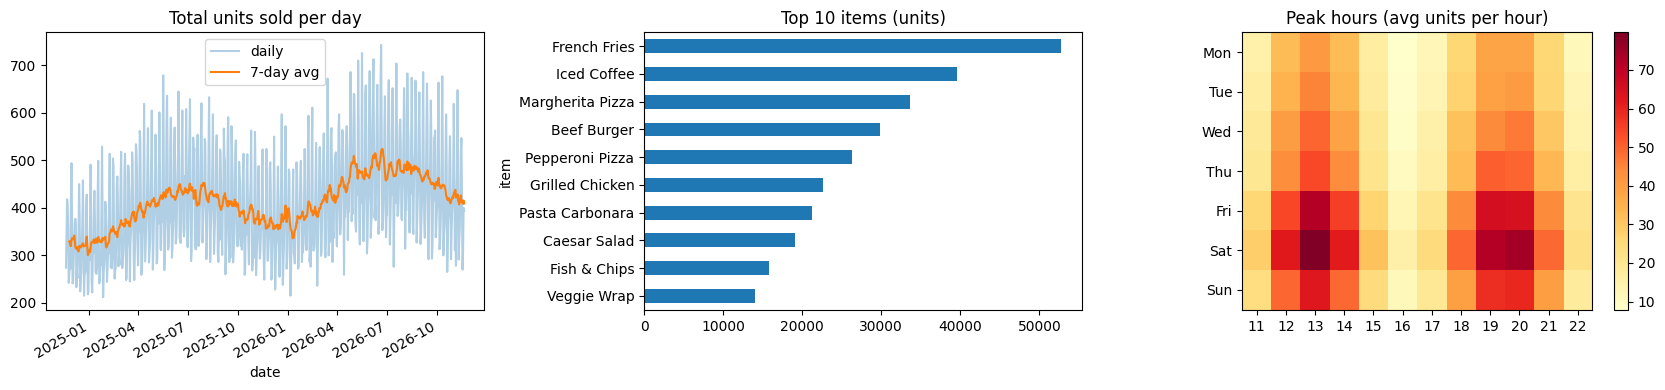

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
tot = daily.groupby("date")["quantity"].sum()
tot.plot(ax=ax[0], alpha=.35, label="daily"); tot.rolling(7).mean().plot(ax=ax[0], label="7-day avg")
ax[0].set_title("Total units sold per day"); ax[0].legend()

daily.groupby("item")["quantity"].sum().sort_values().tail(10).plot.barh(ax=ax[1])
ax[1].set_title("Top 10 items (units)")

hm = hourly.pivot(index="dow", columns="hour", values="avg_units")
hm.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][: len(hm)] if len(hm) == 7 else hm.index
im = ax[2].imshow(hm.values, aspect="auto", cmap="YlOrRd")
ax[2].set_xticks(range(len(hm.columns))); ax[2].set_xticklabels(hm.columns)
ax[2].set_yticks(range(len(hm.index))); ax[2].set_yticklabels(hm.index)
ax[2].set_title("Peak hours (avg units per hour)"); plt.colorbar(im, ax=ax[2])
plt.tight_layout(); plt.show()

## 5. Build the modelling table

* Fill in **zero-sales days** (a missing row means "sold 0", not "unknown") so lags are correct.
* Features use **only past information**: yesterday's sales, same weekday last week, rolling averages, calendar effects.
* Everything is `shift`ed so the model never peeks at the day it is predicting.

In [ ]:
def build_panel(daily):
    items = sorted(daily["item"].unique())
    all_days = pd.date_range(daily["date"].min(), daily["date"].max() + pd.Timedelta(days=1))  # +1 = tomorrow
    grid = pd.MultiIndex.from_product([all_days, items], names=["date", "item"]).to_frame(index=False)
    p = grid.merge(daily[["date", "item", "quantity"]], on=["date", "item"], how="left")
    last = daily["date"].max()
    p.loc[p["date"] <= last, "quantity"] = p.loc[p["date"] <= last, "quantity"].fillna(0)   # tomorrow stays NaN
    return p.sort_values(["item", "date"]).reset_index(drop=True)


def add_features(p):
    p = p.copy()
    g = p.groupby("item")["quantity"]
    for lag in [1, 2, 7, 14, 21, 28]:
        p[f"lag_{lag}"] = g.shift(lag)
    for w in [7, 14, 28]:
        p[f"roll_mean_{w}"] = g.transform(lambda s: s.shift(1).rolling(w).mean())
    p["roll_std_7"] = g.transform(lambda s: s.shift(1).rolling(7).std())
    p["same_dow_avg_4w"] = p[["lag_7", "lag_14", "lag_21", "lag_28"]].mean(axis=1)
    p["dow"] = p["date"].dt.dayofweek
    p["is_weekend"] = (p["dow"] >= 4).astype(int)           # Fri-Sun are the busy nights
    p["month"] = p["date"].dt.month
    p["day_of_month"] = p["date"].dt.day
    p["item_id"] = p["item"].astype("category").cat.codes
    return p


FEATURES = ["lag_1", "lag_2", "lag_7", "lag_14", "lag_21", "lag_28", "roll_mean_7", "roll_mean_14",
            "roll_mean_28", "roll_std_7", "same_dow_avg_4w", "dow", "is_weekend", "month", "day_of_month", "item_id"]

panel = add_features(build_panel(daily))
tomorrow = panel["date"].max()
model_df = panel[(panel["date"] < tomorrow)].dropna(subset=FEATURES).reset_index(drop=True)
print("Forecasting date:", tomorrow.date(), "| training rows:", len(model_df))

Forecasting date: 2026-11-20 | training rows: 8424


## 6. Train and evaluate (time-based split, no shuffling)

```
|-------------- train --------------|-- validation (28d) --|-- test (28d) --|
```
* **train**: fit the model
* **validation**: measure typical forecast error → sets the safety buffer for prep
* **test**: untouched final exam

Baselines to beat: **"same as last week"** and **"7-day average"**: what a manager would do by gut feel.

In [ ]:
TEST_DAYS, VAL_DAYS = 28, 28
last_day = model_df["date"].max()
test_start = last_day - pd.Timedelta(days=TEST_DAYS - 1)
val_start = test_start - pd.Timedelta(days=VAL_DAYS)

train = model_df[model_df["date"] < val_start]
val   = model_df[(model_df["date"] >= val_start) & (model_df["date"] < test_start)]
test  = model_df[model_df["date"] >= test_start]
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")

def make_model():
    return HistGradientBoostingRegressor(
        loss="poisson",              # demand is a non-negative count
        learning_rate=0.05, max_iter=400, max_leaf_nodes=24, min_samples_leaf=30,
        l2_regularization=1.0, categorical_features=[FEATURES.index("item_id")],
        early_stopping=False, random_state=0)

model = make_model().fit(train[FEATURES], train["quantity"])
val["pred"]  = model.predict(val[FEATURES])
test["pred"] = model.predict(test[FEATURES])

train 7,752 | val 336 | test 336


In [ ]:
def metrics(y, yhat):
    mae = np.mean(np.abs(y - yhat))
    wape = np.abs(y - yhat).sum() / y.sum()          # "average % error" weighted by volume
    bias = (yhat - y).mean()                          # >0 = over-forecast (waste risk)
    return dict(MAE=mae, WAPE_pct=100 * wape, Bias=bias)

results = {
    "ML model (gradient boosting)": metrics(test["quantity"], test["pred"]),
    "Baseline: same day last week": metrics(test["quantity"], test["lag_7"]),
    "Baseline: 7-day average":      metrics(test["quantity"], test["roll_mean_7"]),
    "Baseline: avg of last 4 same weekdays": metrics(test["quantity"], test["same_dow_avg_4w"]),
}
results_df = pd.DataFrame(results).T.round(2)
results_df.index.name = "method"
results_df

,MAE,WAPE_pct,Bias
method,,,
ML model (gradient boosting),5.10,14.59,-0.62
Baseline: same day last week,6.99,20.00,0.24
Baseline: 7-day average,8.28,23.70,0.05
Baseline: avg of last 4 same weekdays,5.17,14.80,0.89


,MAE,WAPE_pct,Bias
item,,,
French Fries,6.61,8.95,-1.83
Margherita Pizza,4.95,10.66,-0.08
Iced Coffee,7.04,12.93,-0.03
Pasta Carbonara,4.34,14.20,-1.08
Grilled Chicken,4.67,14.35,-0.28
Beef Burger,6.24,14.75,-0.42
Pepperoni Pizza,5.93,16.59,-0.60
Fish & Chips,3.67,17.38,0.06
Cheesecake,3.23,18.44,-0.10


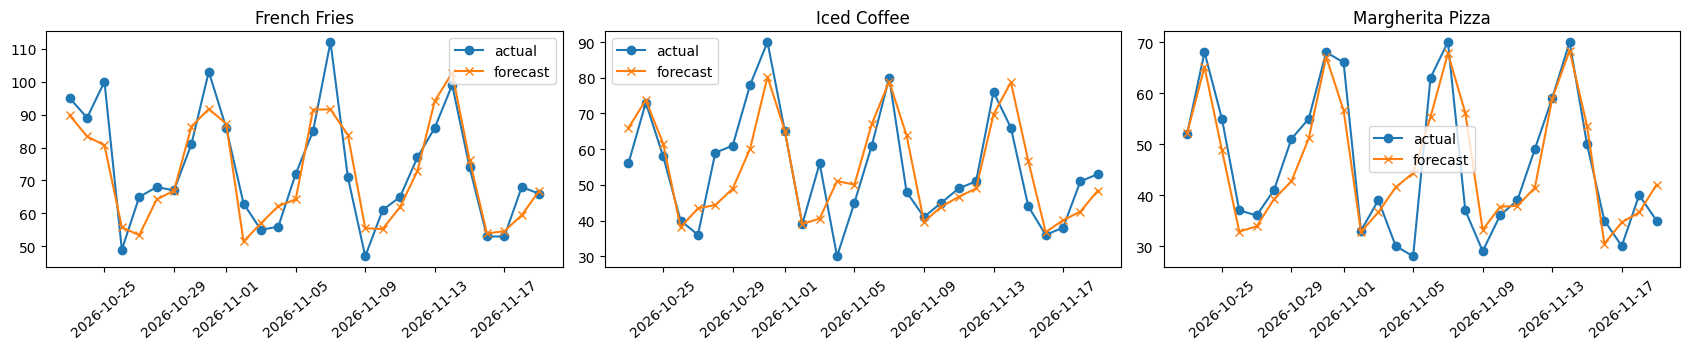

In [ ]:
# Per-item accuracy of the ML model
per_item = (test.groupby("item").apply(lambda d: pd.Series(metrics(d["quantity"], d["pred"])))
                .round(2).sort_values("WAPE_pct"))
display(per_item)

# Visual check: actual vs predicted for the 3 biggest items
top3 = test.groupby("item")["quantity"].sum().nlargest(3).index
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for a, it in zip(axes, top3):
    d = test[test["item"] == it]
    a.plot(d["date"], d["quantity"], marker="o", label="actual")
    a.plot(d["date"], d["pred"], marker="x", label="forecast")
    a.set_title(it); a.tick_params(axis="x", rotation=40); a.legend()
plt.tight_layout(); plt.show()

## 7. Turn forecasts into a prep plan (the business metric)

A forecast is only the *average* expectation. To avoid sell-outs we prep a bit extra:

`prep = forecast + z × typical_error`

where `z` comes from the chosen **service level** (e.g. 85% → "we want to cover demand on ~85% of days").
Higher service level → fewer sell-outs, but more leftover food. We measure both on the **test period**:

* **Waste** = units prepped but not sold
* **Shortage** = units customers wanted but we ran out of

In [ ]:
from scipy.stats import norm

# typical error per item, measured on the VALIDATION window (not the test window -> no leakage)
sigma = (val["quantity"] - val["pred"]).groupby(val["item"]).std().rename("sigma")
test = test.merge(sigma, on="item", how="left")
test["sigma"] = test["sigma"].fillna(sigma.mean())

def simulate(prep, actual):
    waste = np.maximum(prep - actual, 0).sum()
    short = np.maximum(actual - prep, 0).sum()
    return waste, short

rows = []
for sl in [0.5, 0.7, 0.8, 0.85, 0.9, 0.95]:
    prep = np.ceil(np.maximum(test["pred"] + norm.ppf(sl) * test["sigma"], 0))
    w, s = simulate(prep, test["quantity"])
    rows.append((f"ML model @ {int(sl*100)}% service", w, s))

for name, col in [("Same as last week", "lag_7"), ("7-day average", "roll_mean_7")]:
    w, s = simulate(np.ceil(test[col]), test["quantity"])
    rows.append((f"Baseline: {name}", w, s))

policy = pd.DataFrame(rows, columns=["policy", "wasted_units", "shortage_units"])
policy["wasted_units"] = policy["wasted_units"].round(0).astype(int)
policy["shortage_units"] = policy["shortage_units"].round(0).astype(int)
policy

,policy,wasted_units,shortage_units
0,ML model @ 50% service,831,876
1,ML model @ 70% service,1583,420
2,ML model @ 80% service,2145,249
3,ML model @ 85% service,2516,170
4,ML model @ 90% service,3016,109
5,ML model @ 95% service,3782,37
6,Baseline: Same as last week,1214,1133
7,Baseline: 7-day average,1473,1317


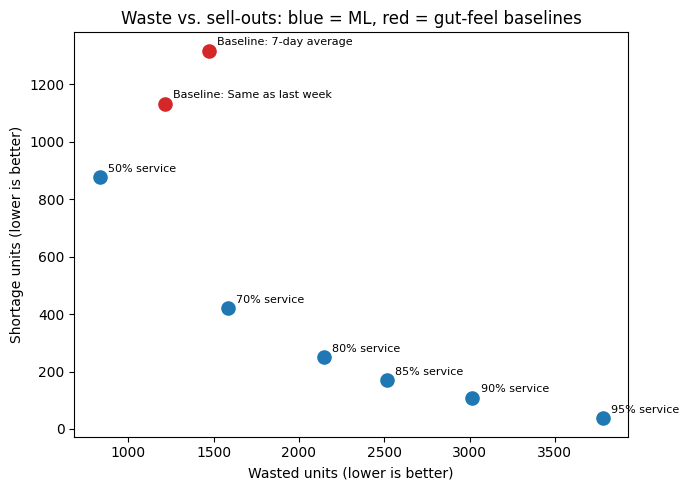

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
for _, r in policy.iterrows():
    base = r["policy"].startswith("Baseline")
    ax.scatter(r["wasted_units"], r["shortage_units"], s=90, c="tab:red" if base else "tab:blue")
    ax.annotate(r["policy"].replace("ML model @ ", ""), (r["wasted_units"], r["shortage_units"]),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("Wasted units (lower is better)"); ax.set_ylabel("Shortage units (lower is better)")
ax.set_title("Waste vs. sell-outs: blue = ML, red = gut-feel baselines")
plt.tight_layout(); plt.show()

## 8. Refit on all data and forecast **tomorrow**

In [ ]:
final_model = make_model().fit(model_df[FEATURES], model_df["quantity"])

tmr = panel[panel["date"] == tomorrow].copy()
tmr["forecast"] = np.maximum(final_model.predict(tmr[FEATURES]), 0)

# Residual spread for the safety buffer: validation + test residuals of the backtest model
resid = pd.concat([val, test.drop(columns="sigma")])
sigma_final = (resid["quantity"] - resid["pred"]).groupby(resid["item"]).std().rename("sigma")

forecast_tomorrow = (tmr[["date", "item", "forecast", "same_dow_avg_4w", "lag_7"]]
                     .merge(sigma_final, on="item", how="left")
                     .rename(columns={"same_dow_avg_4w": "avg_last_4_same_weekdays", "lag_7": "same_day_last_week"}))
forecast_tomorrow["sigma"] = forecast_tomorrow["sigma"].fillna(sigma_final.mean())

print("Prep forecast for", tomorrow.strftime("%A %d %b %Y"))
forecast_tomorrow.assign(prep_85pct=lambda d: np.ceil(d["forecast"] + norm.ppf(0.85) * d["sigma"])) \
                 .round(1).sort_values("forecast", ascending=False)

Prep forecast for Friday 20 Nov 2026


,date,item,forecast,avg_last_4_same_weekdays,same_day_last_week,sigma,prep_85pct
4,2026-11-20,French Fries,94.5,86.8,86.0,9.5,105.0
6,2026-11-20,Iced Coffee,64.6,67.8,76.0,9.1,75.0
7,2026-11-20,Margherita Pizza,58.0,57.2,59.0,7.6,66.0
0,2026-11-20,Beef Burger,51.3,52.5,56.0,7.1,59.0
5,2026-11-20,Grilled Chicken,37.9,39.2,36.0,5.8,44.0
9,2026-11-20,Pepperoni Pizza,37.3,37.0,42.0,7.8,46.0
8,2026-11-20,Pasta Carbonara,34.9,38.0,38.0,6.1,42.0
1,2026-11-20,Caesar Salad,31.5,30.8,34.0,7.3,40.0
3,2026-11-20,Fish & Chips,23.3,22.8,26.0,5.1,29.0
11,2026-11-20,Veggie Wrap,21.8,21.2,24.0,5.8,28.0


## 9. Which signals matter? (permutation importance, explainable to non-technical people)

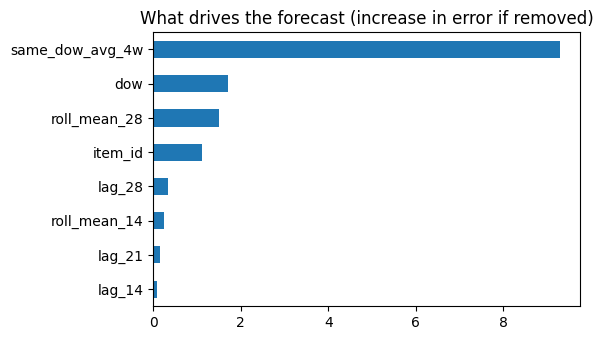

In [ ]:
from sklearn.inspection import permutation_importance
sample = test.sample(min(len(test), 1500), random_state=0)
pi = permutation_importance(model, sample[FEATURES], sample["quantity"], n_repeats=5, random_state=0,
                            scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.tail(8).plot.barh(figsize=(6, 3.5), title="What drives the forecast (increase in error if removed)")
plt.tight_layout(); plt.show()

## 10. Save everything the dashboard needs

In [ ]:
# backtest table used by the dashboard (actual vs forecast + baseline + error spread)
backtest = test[["date", "item", "quantity", "pred", "lag_7", "sigma"]].rename(
    columns={"quantity": "actual", "pred": "forecast", "lag_7": "same_day_last_week"})

daily.to_csv(f"{OUT}/daily_sales.csv", index=False)
hourly.to_csv(f"{OUT}/hourly_sales.csv", index=False)
forecast_tomorrow.to_csv(f"{OUT}/forecast_tomorrow.csv", index=False)
backtest.to_csv(f"{OUT}/backtest.csv", index=False)
results_df.reset_index().to_csv(f"{OUT}/metrics.csv", index=False)
clean_log.to_csv(f"{OUT}/cleaning_log.csv", index=False)
joblib.dump(final_model, f"{OUT}/model.joblib")
print(os.listdir(OUT))

['backtest.csv', 'model.joblib', 'hourly_sales.csv', 'forecast_tomorrow.csv', 'daily_sales.csv', 'metrics.csv', 'cleaning_log.csv']


## 11. Streamlit dashboard

The next cell writes `app.py`. The one after launches it and gives you a public link.

In [ ]:
%%writefile app.py
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st
from pathlib import Path
from scipy.stats import norm

OUT = Path("outputs")
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

st.set_page_config(page_title="Restaurant Demand Planner", page_icon="🍽️", layout="wide")


@st.cache_data
def load():
    daily = pd.read_csv(OUT / "daily_sales.csv", parse_dates=["date"])
    hourly = pd.read_csv(OUT / "hourly_sales.csv")
    fc = pd.read_csv(OUT / "forecast_tomorrow.csv", parse_dates=["date"])
    bt = pd.read_csv(OUT / "backtest.csv", parse_dates=["date"])
    metrics = pd.read_csv(OUT / "metrics.csv")
    clog = pd.read_csv(OUT / "cleaning_log.csv")
    return daily, hourly, fc, bt, metrics, clog


daily, hourly, fc, bt, metrics, clog = load()
has_revenue = daily["revenue"].fillna(0).sum() > 0

st.title("🍽️ Restaurant Demand Planner")
st.caption("Sales trends, peak hours and a prep suggestion for tomorrow.")

# ---------------- sidebar ----------------
st.sidebar.header("Filters")
dmin, dmax = daily["date"].min().date(), daily["date"].max().date()
default_start = max(dmin, (daily["date"].max() - pd.Timedelta(days=89)).date())
start, end = st.sidebar.date_input("Date range", (default_start, dmax), min_value=dmin, max_value=dmax)
all_items = sorted(daily["item"].unique())
chosen = st.sidebar.multiselect("Items", all_items, default=all_items)

f = daily[(daily["date"].dt.date >= start) & (daily["date"].dt.date <= end) & (daily["item"].isin(chosen))]

tab1, tab2, tab3, tab4 = st.tabs(["📈 Sales overview", "⏰ Peak hours & patterns", "🎯 How good is the forecast?", "🧑‍🍳 Prep plan for tomorrow"])

# ---------------- tab 1: overview ----------------
with tab1:
    n_days = max(f["date"].nunique(), 1)
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Units sold", f"{int(f['quantity'].sum()):,}")
    c2.metric("Avg units / day", f"{f['quantity'].sum() / n_days:,.0f}")
    if has_revenue:
        c3.metric("Revenue", f"{f['revenue'].sum():,.0f}")
    else:
        c3.metric("Items on menu", f"{f['item'].nunique()}")
    by_dow = f.groupby([f["date"].dt.dayofweek, "date"])["quantity"].sum().groupby(level=0).mean()
    c4.metric("Busiest weekday", DAYS[int(by_dow.idxmax())] if len(by_dow) else "-")

    tot = f.groupby("date", as_index=False)["quantity"].sum()
    tot["7-day average"] = tot["quantity"].rolling(7).mean()
    fig = go.Figure()
    fig.add_bar(x=tot["date"], y=tot["quantity"], name="Daily units", opacity=0.35)
    fig.add_scatter(x=tot["date"], y=tot["7-day average"], name="7-day average", line=dict(width=3))
    fig.update_layout(title="Units sold per day", height=380, margin=dict(t=50, b=10), legend=dict(orientation="h"))
    st.plotly_chart(fig, width="stretch")

    left, right = st.columns(2)
    top = f.groupby("item", as_index=False)["quantity"].sum().sort_values("quantity").tail(10)
    left.plotly_chart(px.bar(top, x="quantity", y="item", orientation="h", title="Top 10 items by units sold")
                      .update_layout(height=400, margin=dict(t=50, b=10)), width="stretch")
    if has_revenue:
        rev = f.groupby("item", as_index=False)["revenue"].sum().sort_values("revenue").tail(10)
        right.plotly_chart(px.bar(rev, x="revenue", y="item", orientation="h", title="Top 10 items by revenue")
                           .update_layout(height=400, margin=dict(t=50, b=10)), width="stretch")
    else:
        mix = f.groupby("item")["quantity"].sum().nlargest(8)
        right.plotly_chart(px.pie(values=mix.values, names=mix.index, title="Menu mix (top 8)")
                           .update_layout(height=400), width="stretch")

    with st.expander("How was the data cleaned?"):
        st.dataframe(clog, hide_index=True, width="stretch")

# ---------------- tab 2: peak hours ----------------
with tab2:
    hm = hourly.pivot(index="dow", columns="hour", values="avg_units").reindex(range(7))
    hm.index = DAYS
    fig = px.imshow(hm, aspect="auto", color_continuous_scale="YlOrRd", labels=dict(x="Hour of day", y="", color="Avg units"),
                    title="Average units sold per hour: darker = busier")
    fig.update_layout(height=380, margin=dict(t=50, b=10))
    st.plotly_chart(fig, width="stretch")

    slots = hourly.sort_values("avg_units", ascending=False).head(5)
    st.markdown("**Busiest 5 time slots → schedule extra staff and have food ready:**")
    for _, r in slots.iterrows():
        st.write(f"- **{DAYS[int(r['dow'])]} {int(r['hour']):02d}:00-{int(r['hour']) + 1:02d}:00**: about {r['avg_units']:.0f} units/hour")

    pivot = f.assign(dow=f["date"].dt.dayofweek).groupby(["item", "dow"])["quantity"].mean().unstack().reindex(columns=range(7))
    pivot.columns = DAYS
    pivot = pivot.div(pivot.mean(axis=1), axis=0)          # 1.0 = that item's normal day
    fig2 = px.imshow(pivot, aspect="auto", color_continuous_scale="RdBu_r", color_continuous_midpoint=1,
                     title="Which items spike on which weekday? (1.0 = the item's average day)")
    fig2.update_layout(height=420, margin=dict(t=50, b=10))
    st.plotly_chart(fig2, width="stretch")

# ---------------- tab 3: forecast accuracy ----------------
with tab3:
    m = metrics.set_index("method")
    ml = m.loc["ML model (gradient boosting)"]
    gut = m.loc["Baseline: same day last week"]
    c1, c2, c3 = st.columns(3)
    c1.metric("Forecast error (ML)", f"{ml['WAPE_pct']:.0f}%")
    c2.metric("Error if 'same as last week'", f"{gut['WAPE_pct']:.0f}%")
    improve = 100 * (gut["WAPE_pct"] - ml["WAPE_pct"]) / gut["WAPE_pct"]
    c3.metric("Improvement", f"{improve:.0f}% fewer mistakes")
    st.info("Error = how far off the forecast is, on average, as a % of what was sold. "
            "Measured on the last 4 weeks of data the model had **never seen**.")
    st.dataframe(metrics.rename(columns={"WAPE_pct": "Error %", "Bias": "Avg over(+)/under(-) forecast"}).round(2),
                 hide_index=True, width="stretch")

    it = st.selectbox("Look at an item", sorted(bt["item"].unique()))
    d = bt[bt["item"] == it]
    fig = go.Figure()
    fig.add_scatter(x=d["date"], y=d["actual"], mode="lines+markers", name="Actually sold")
    fig.add_scatter(x=d["date"], y=d["forecast"], mode="lines+markers", name="Forecast")
    fig.add_scatter(x=d["date"], y=d["same_day_last_week"], mode="lines", name="Same day last week", line=dict(dash="dot"))
    fig.update_layout(title=f"{it}: forecast vs reality (test period)", height=380, margin=dict(t=50, b=10),
                      legend=dict(orientation="h"))
    st.plotly_chart(fig, width="stretch")

# ---------------- tab 4: prep plan ----------------
with tab4:
    tdate = fc["date"].iloc[0]
    st.subheader(f"Prep suggestion for {tdate.strftime('%A, %d %B %Y')}")

    sl = st.slider("Service level: how often do you want to avoid running out?", 50, 99, 85, format="%d%%",
                   help="Higher = fewer sell-outs, but more leftover food.")
    z = norm.ppf(sl / 100)

    plan = fc.copy()
    plan["Prep this many"] = np.ceil(np.maximum(plan["forecast"] + z * plan["sigma"], 0)).astype(int)
    plan["Expected demand"] = plan["forecast"].round(0).astype(int)
    plan["Likely range"] = [f"{max(0, round(a - 1.28 * s))} - {round(a + 1.28 * s)}"
                            for a, s in zip(plan["forecast"], plan["sigma"])]
    plan["Last week same day"] = plan["same_day_last_week"].round(0).astype(int)
    show = plan[["item", "Expected demand", "Likely range", "Prep this many", "Last week same day"]] \
        .rename(columns={"item": "Item"}).sort_values("Prep this many", ascending=False)

    c1, c2 = st.columns([3, 2])
    with c1:
        st.dataframe(show, hide_index=True, width="stretch", height=470)
        st.download_button("⬇️ Download prep sheet (CSV)", show.to_csv(index=False), "prep_plan.csv", "text/csv")
    with c2:
        fig = go.Figure()
        s2 = show.sort_values("Prep this many")
        fig.add_bar(y=s2["Item"], x=s2["Expected demand"], orientation="h", name="Expected demand")
        fig.add_bar(y=s2["Item"], x=s2["Prep this many"] - s2["Expected demand"], orientation="h", name="Safety buffer")
        fig.update_layout(barmode="stack", height=470, margin=dict(t=10, b=10), legend=dict(orientation="h"))
        st.plotly_chart(fig, width="stretch")

    # What would this service level have done over the last 4 weeks?
    st.markdown("#### What would this setting have meant over the last 4 weeks?")
    prep_ml = np.ceil(np.maximum(bt["forecast"] + z * bt["sigma"], 0))
    prep_gut = np.ceil(bt["same_day_last_week"])
    def stats(prep):
        waste = np.maximum(prep - bt["actual"], 0).sum()
        short = np.maximum(bt["actual"] - prep, 0).sum()
        return waste, short
    w1, s1 = stats(prep_ml); w2, s2_ = stats(prep_gut)
    k1, k2, k3, k4 = st.columns(4)
    k1.metric("Wasted units (this plan)", f"{w1:,.0f}", f"{w1 - w2:,.0f} vs last-week rule", delta_color="inverse")
    k2.metric("Missed sales (this plan)", f"{s1:,.0f}", f"{s1 - s2_:,.0f} vs last-week rule", delta_color="inverse")
    k3.metric("Wasted units (last-week rule)", f"{w2:,.0f}")
    k4.metric("Missed sales (last-week rule)", f"{s2_:,.0f}")
    st.caption("Wasted = prepped but not sold. Missed = customers wanted it but we had run out.")

Writing app.py


### Launch in Colab
Colab can't open `localhost` directly, so we expose the app through a tunnel.
When the link opens, a page may ask for a **Tunnel Password**: use the IP address printed below.

In [ ]:
import subprocess, time

# Download and install cloudflared
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared-linux-amd64

# Start Streamlit in the background
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
                 stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
time.sleep(3)

# Expose port 8501 via Cloudflare Tunnel
!./cloudflared-linux-amd64 tunnel --url http://localhost:8501

2026-11-20T14:04:54Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-20T14:04:54Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-20T14:04:58Z INF +--------------------------------------------------------------------------------------------+
2026-11-20T14:04:58Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-20T14:04:58Z INF |  https://diving-nail-ourselves-picks.trycloudflare.com